# Day 22: Handle Missing Values

**Internship:** VEDA AI & ML Internship  
**Task:** 22 – Handle Missing Values

## Objective
To identify, analyze, and handle missing values in a dataset using Pandas.

## Tools Used
- Python
- Pandas
- NumPy
- Jupyter Notebook

## Dataset
Titanic dataset

## Learning Outcomes
- Identify missing values.
- Calculate missing-value counts and percentages.
- Handle numerical and categorical missing values.
- Compare the dataset before and after cleaning.

In [1]:
import pandas as pd
import numpy as np

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 1. Dataset Exploration

Inspect the dataset structure, column names, data types, and sample records before handling missing values.

In [3]:
print("First 5 rows:")
display(df.head())

print("Dataset information:")
df.info()

print("\nDataset dimensions:", df.shape)

First 5 rows:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB

Dataset dimensions: (891, 12)


## 2. Missing Value Analysis

Identify the number of missing values in each column using `isnull()` and `sum()`.

In [4]:
missing_count = df.isnull().sum()

print("Missing values in each column:")
display(missing_count[missing_count > 0])

Missing values in each column:


Age         177
Cabin       687
Embarked      2
dtype: int64

In [5]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_analysis = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": missing_percentage.round(2)
})

missing_analysis = missing_analysis[
    missing_analysis["Missing Count"] > 0
].sort_values(by="Missing Percentage", ascending=False)

display(missing_analysis)

,Missing Count,Missing Percentage
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22


## 3. Visualize Missing Values

Display the number of missing values in each affected column using a bar chart.

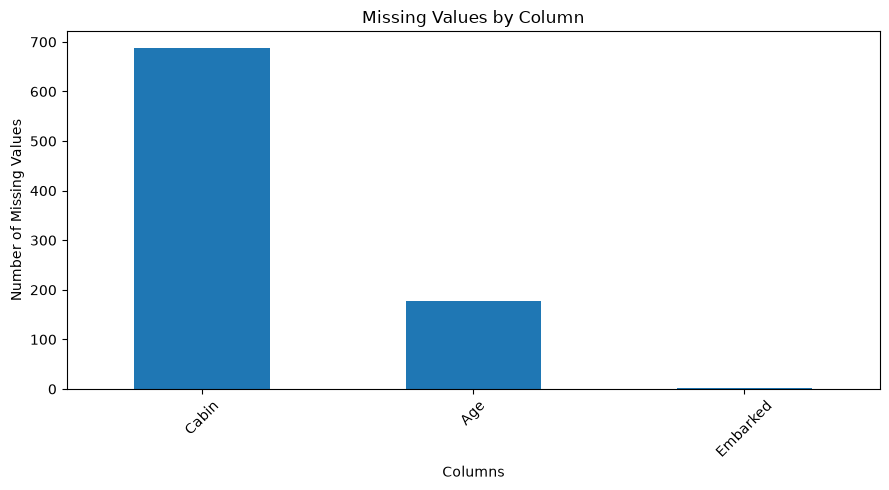

In [6]:
import matplotlib.pyplot as plt

missing_count = df.isnull().sum()
missing_count = missing_count[missing_count > 0].sort_values(
    ascending=False
)

missing_count.plot(kind="bar", figsize=(9, 5))

plt.title("Missing Values by Column")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 4. Create a Backup

Preserve the original dataset so that the cleaned data can be compared with the original data.

In [7]:
df_original = df.copy()

print("Original dataset shape:", df_original.shape)
print("Total missing values:", df_original.isnull().sum().sum())

Original dataset shape: (891, 12)
Total missing values: 866


## 5. Handle Numerical Missing Values

Fill missing values in the `Age` column using the median age.

**Reason:** The median is robust to extreme values and is a suitable choice when numerical data may be skewed.

In [8]:
age_median = df["Age"].median()

df["Age"] = df["Age"].fillna(age_median)

print("Median age used:", age_median)
print("Missing values in Age after cleaning:", df["Age"].isnull().sum())

Median age used: 28.0
Missing values in Age after cleaning: 0


## 6. Handle Categorical Missing Values

Fill missing values in the `Embarked` column using the mode.

**Reason:** The mode is appropriate for categorical data because it replaces missing entries with the most frequent category.

In [9]:
embarked_mode = df["Embarked"].mode()[0]

df["Embarked"] = df["Embarked"].fillna(embarked_mode)

print("Mode used for Embarked:", embarked_mode)
print("Missing values in Embarked after cleaning:", df["Embarked"].isnull().sum())

Mode used for Embarked: S
Missing values in Embarked after cleaning: 0


## 7. Handle Columns with Extensive Missing Data

Remove the `Cabin` column because a large proportion of its values are missing in this dataset.

**Reason:** Removing a heavily incomplete column can be reasonable when the column is not required for the current analysis. In a real machine-learning project, evaluate its usefulness before discarding it.

In [10]:
if "Cabin" in df.columns:
    df.drop(columns=["Cabin"], inplace=True)

print("Cabin column removed.")
print("Updated dataset shape:", df.shape)

Cabin column removed.
Updated dataset shape: (891, 11)


## 8. Verify the Cleaned Dataset

Check the remaining missing values and confirm that the selected cleaning operations worked.

In [11]:
remaining_missing = df.isnull().sum()

print("Remaining missing values:")
display(remaining_missing[remaining_missing > 0])

print("Total remaining missing values:", df.isnull().sum().sum())

Remaining missing values:


Series([], dtype: int64)

Total remaining missing values: 0


## 9. Before and After Comparison

Compare the original and cleaned datasets by checking their dimensions and total missing values.

In [12]:
comparison = pd.DataFrame({
    "Metric": [
        "Number of Rows",
        "Number of Columns",
        "Total Missing Values"
    ],
    "Before Cleaning": [
        df_original.shape[0],
        df_original.shape[1],
        df_original.isnull().sum().sum()
    ],
    "After Cleaning": [
        df.shape[0],
        df.shape[1],
        df.isnull().sum().sum()
    ]
})

display(comparison)

,Metric,Before Cleaning,After Cleaning
0,Number of Rows,891,891
1,Number of Columns,12,11
2,Total Missing Values,866,0


## 10. Export the Cleaned Dataset

Save the processed dataset as a CSV file for future analysis.

In [13]:
output_file = "titanic_cleaned.csv"

df.to_csv(output_file, index=False)

print(f"Cleaned dataset saved as: {output_file}")

Cleaned dataset saved as: titanic_cleaned.csv
